# Testing Logistic Regression & Kernel SVM Pipelines

Notebook chạy trực tiếp 2 pipeline chuẩn trên nhánh `main` và đánh giá thống nhất bằng `src/metrics.py` (`threshold = 0.5`):
1. **Logistic Regression**: `run_model_logistic()` từ `src/model_logistic.py`.
2. **Kernel SVM (RBF)**: `run_model_svm()` từ `src/model_svm.py`.
3. **Tổng hợp & so sánh** kết quả trên tập Test của hai pipeline.

In [1]:
import os
import sys
import time
from pathlib import Path

if not Path("src").exists() and Path("../src").exists():
    os.chdir("..")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import FIGURE_DIR
from src.model_logistic import run_model_logistic
from src.model_svm import run_model_svm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print("Working directory:", Path.cwd())

Working directory: D:\DAI_HOC\Uni3\Machine learning\ml-project


## 1. Chạy pipeline Logistic Regression (`src/model_logistic.py`)

Fold 1 -> {'AUPRC': 0.75, 'Recall': 0.893, 'Precision': 0.055, 'F1': 0.104, 'TP': 67, 'FP': 1145, 'FN': 8, 'TN': 44176}


Fold 2 -> {'AUPRC': 0.737, 'Recall': 0.893, 'Precision': 0.049, 'F1': 0.093, 'TP': 67, 'FP': 1298, 'FN': 8, 'TN': 44023}


Fold 3 -> {'AUPRC': 0.697, 'Recall': 0.855, 'Precision': 0.064, 'F1': 0.119, 'TP': 65, 'FP': 952, 'FN': 11, 'TN': 44368}


Fold 4 -> {'AUPRC': 0.757, 'Recall': 0.961, 'Precision': 0.059, 'F1': 0.11, 'TP': 73, 'FP': 1173, 'FN': 3, 'TN': 44147}


Fold 5 -> {'AUPRC': 0.759, 'Recall': 0.934, 'Precision': 0.06, 'F1': 0.113, 'TP': 71, 'FP': 1115, 'FN': 5, 'TN': 44205}


TEST RESULT (MODEL B): {'AUPRC': 0.68, 'Recall': 0.874, 'Precision': 0.056, 'F1': 0.105, 'TP': 83, 'FP': 1403, 'FN': 12, 'TN': 55248}


Saved evaluation figure to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\model_logistic_evaluation.png
Elapsed (Logistic Regression): 7.67s


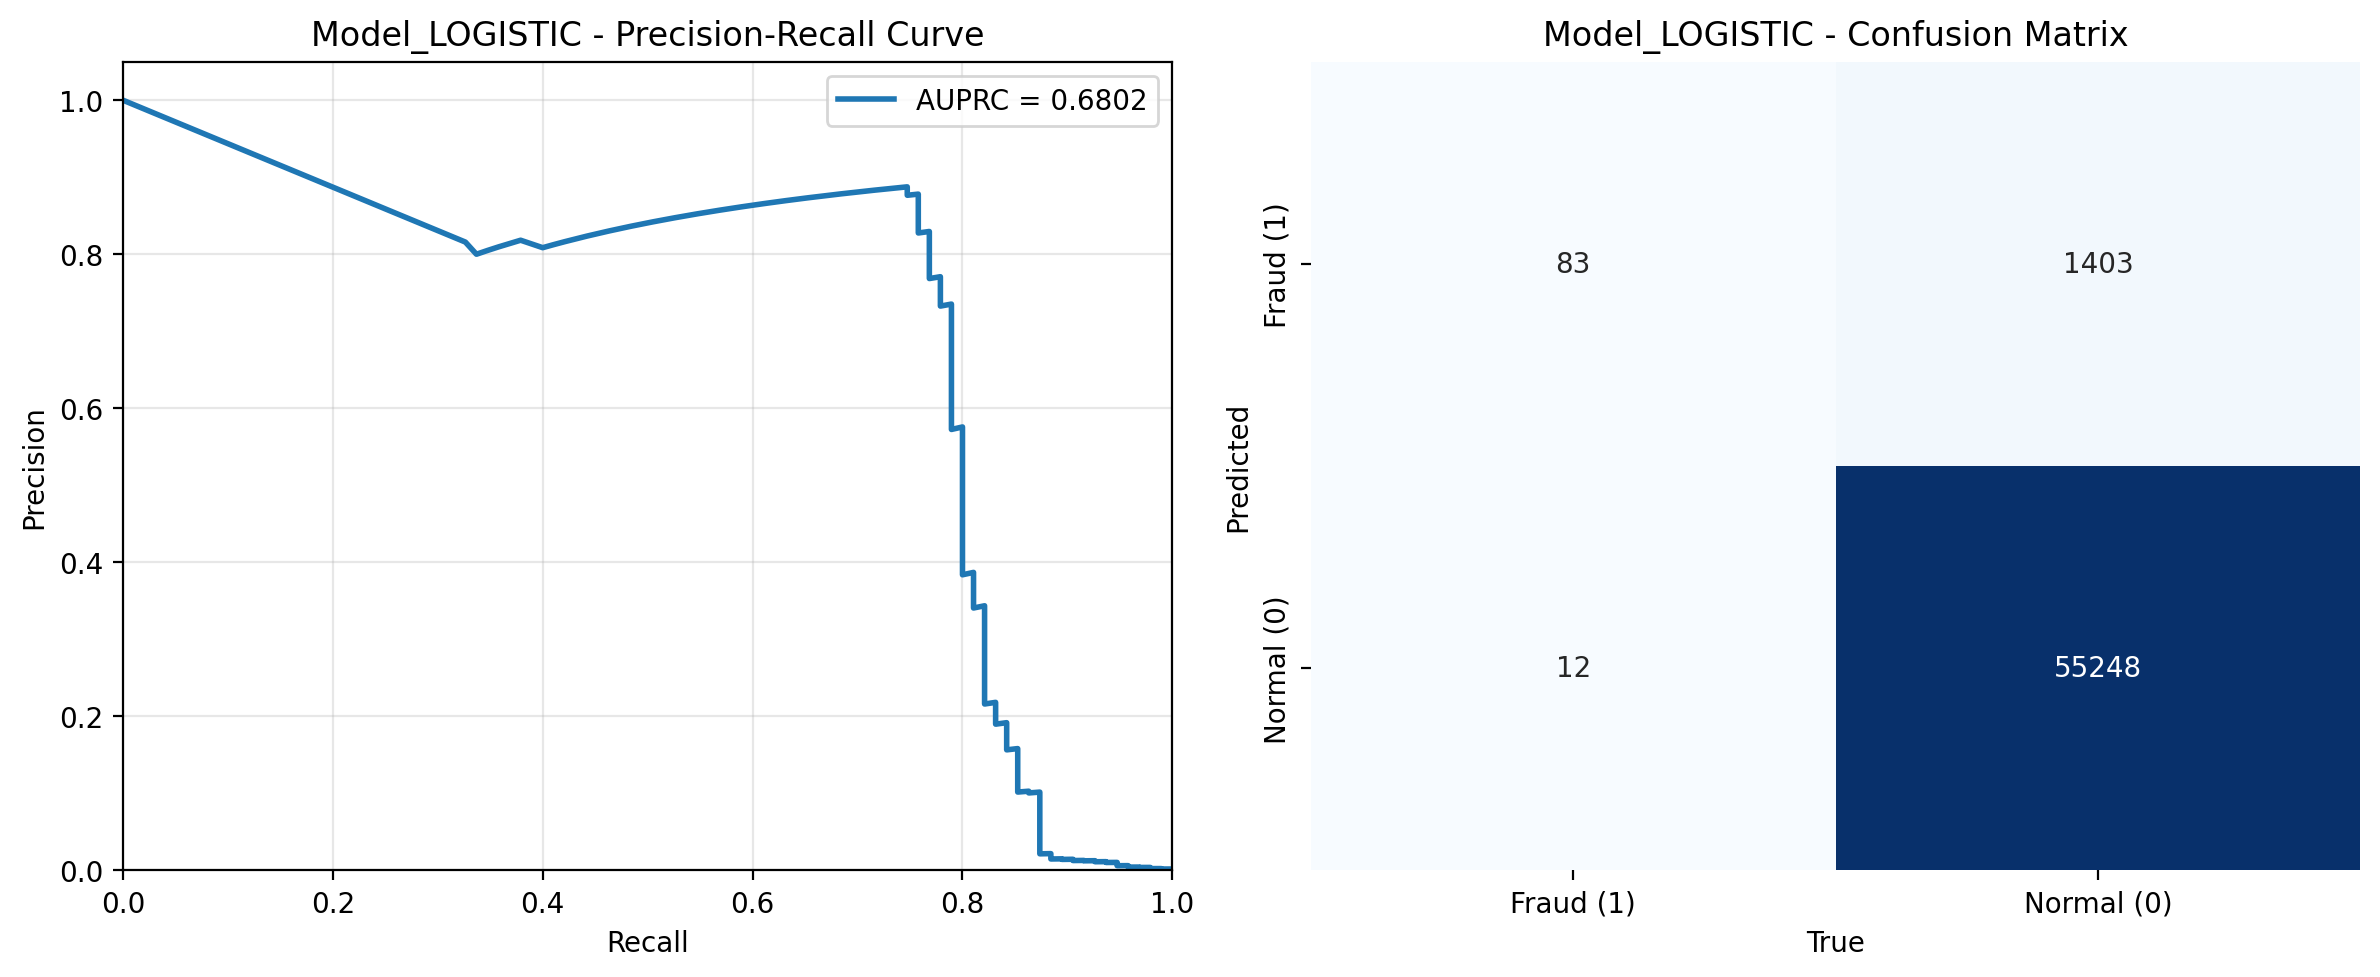

In [2]:
t0 = time.perf_counter()
lr_model, lr_test_metrics = run_model_logistic()
lr_time = round(time.perf_counter() - t0, 2)
print(f"Elapsed (Logistic Regression): {lr_time:.2f}s")
display(Image(filename=str(FIGURE_DIR / "model_logistic_evaluation.png")))

## 2. Chạy pipeline Kernel SVM - RBF (`src/model_svm.py`)

Fold 1 -> {'AUPRC': 0.721, 'Recall': 0.813, 'Precision': 0.735, 'F1': 0.772, 'TP': 61, 'FP': 22, 'FN': 14, 'TN': 45299}


Fold 2 -> {'AUPRC': 0.729, 'Recall': 0.867, 'Precision': 0.492, 'F1': 0.628, 'TP': 65, 'FP': 67, 'FN': 10, 'TN': 45254}


Fold 3 -> {'AUPRC': 0.672, 'Recall': 0.737, 'Precision': 0.622, 'F1': 0.675, 'TP': 56, 'FP': 34, 'FN': 20, 'TN': 45286}


Fold 4 -> {'AUPRC': 0.807, 'Recall': 0.868, 'Precision': 0.66, 'F1': 0.75, 'TP': 66, 'FP': 34, 'FN': 10, 'TN': 45286}


Fold 5 -> {'AUPRC': 0.738, 'Recall': 0.842, 'Precision': 0.64, 'F1': 0.727, 'TP': 64, 'FP': 36, 'FN': 12, 'TN': 45284}


TEST RESULT (MODEL B_2 - SVM): {'AUPRC': 0.719, 'Recall': 0.768, 'Precision': 0.745, 'F1': 0.756, 'TP': 73, 'FP': 25, 'FN': 22, 'TN': 56626}


Saved evaluation figure to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\model_svm_evaluation.png
Elapsed (SVM - RBF): 22.45s


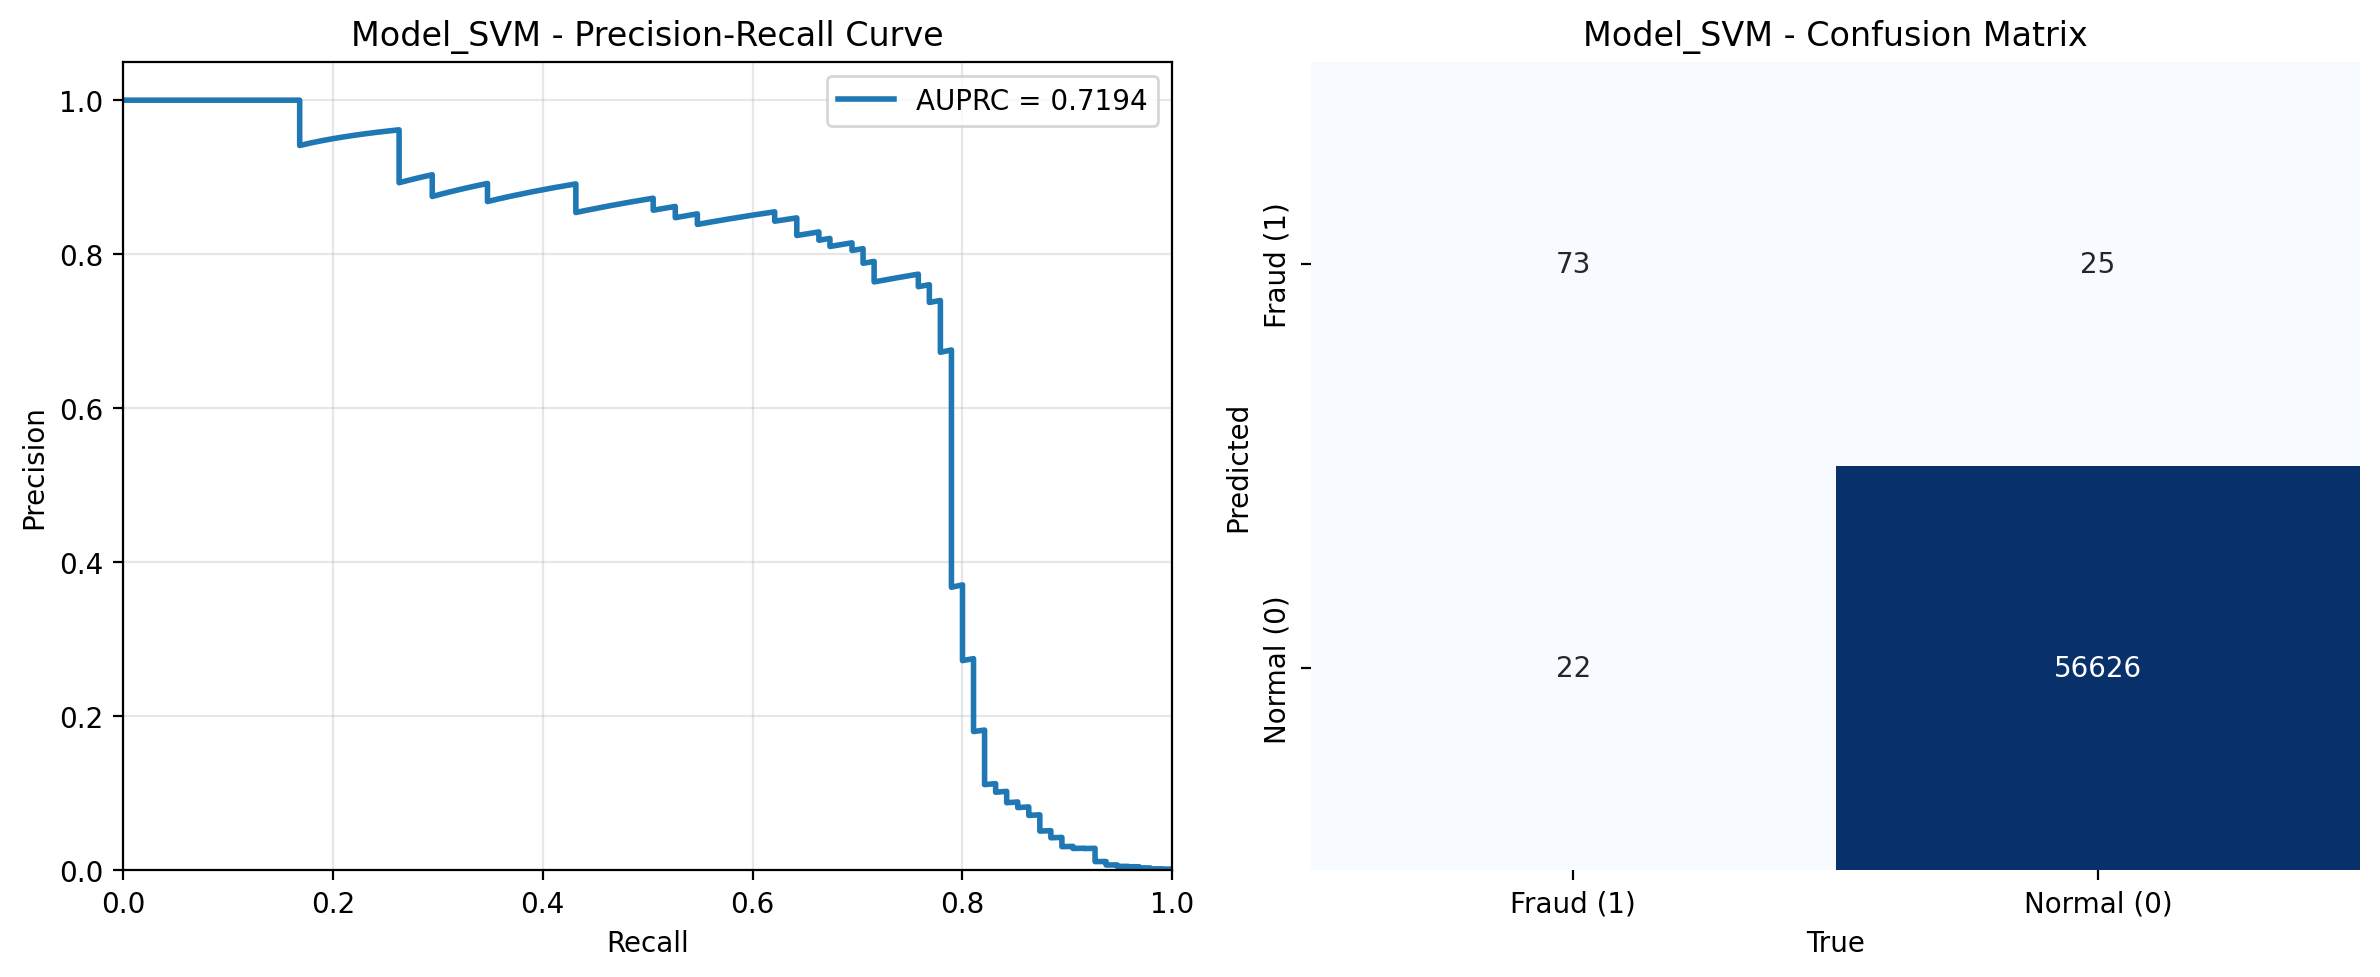

In [3]:
t0 = time.perf_counter()
svm_model, svm_test_metrics = run_model_svm()
svm_time = round(time.perf_counter() - t0, 2)
print(f"Elapsed (SVM - RBF): {svm_time:.2f}s")
display(Image(filename=str(FIGURE_DIR / "model_svm_evaluation.png")))

## 3. Bảng tổng hợp và biểu đồ so sánh 2 pipeline (`t = 0.5`)

,Model,AUPRC,Recall,Precision,F1,TP,FP,FN,TN,Time_s
0,Logistic Regression,0.680,0.874,0.056,0.105,83,1403,12,55248,7.67
1,SVM (RBF),0.719,0.768,0.745,0.756,73,25,22,56626,22.45


Saved comparison chart to: D:\DAI_HOC\Uni3\Machine learning\ml-project\outputs\figures\logistic_vs_svm_comparison.png


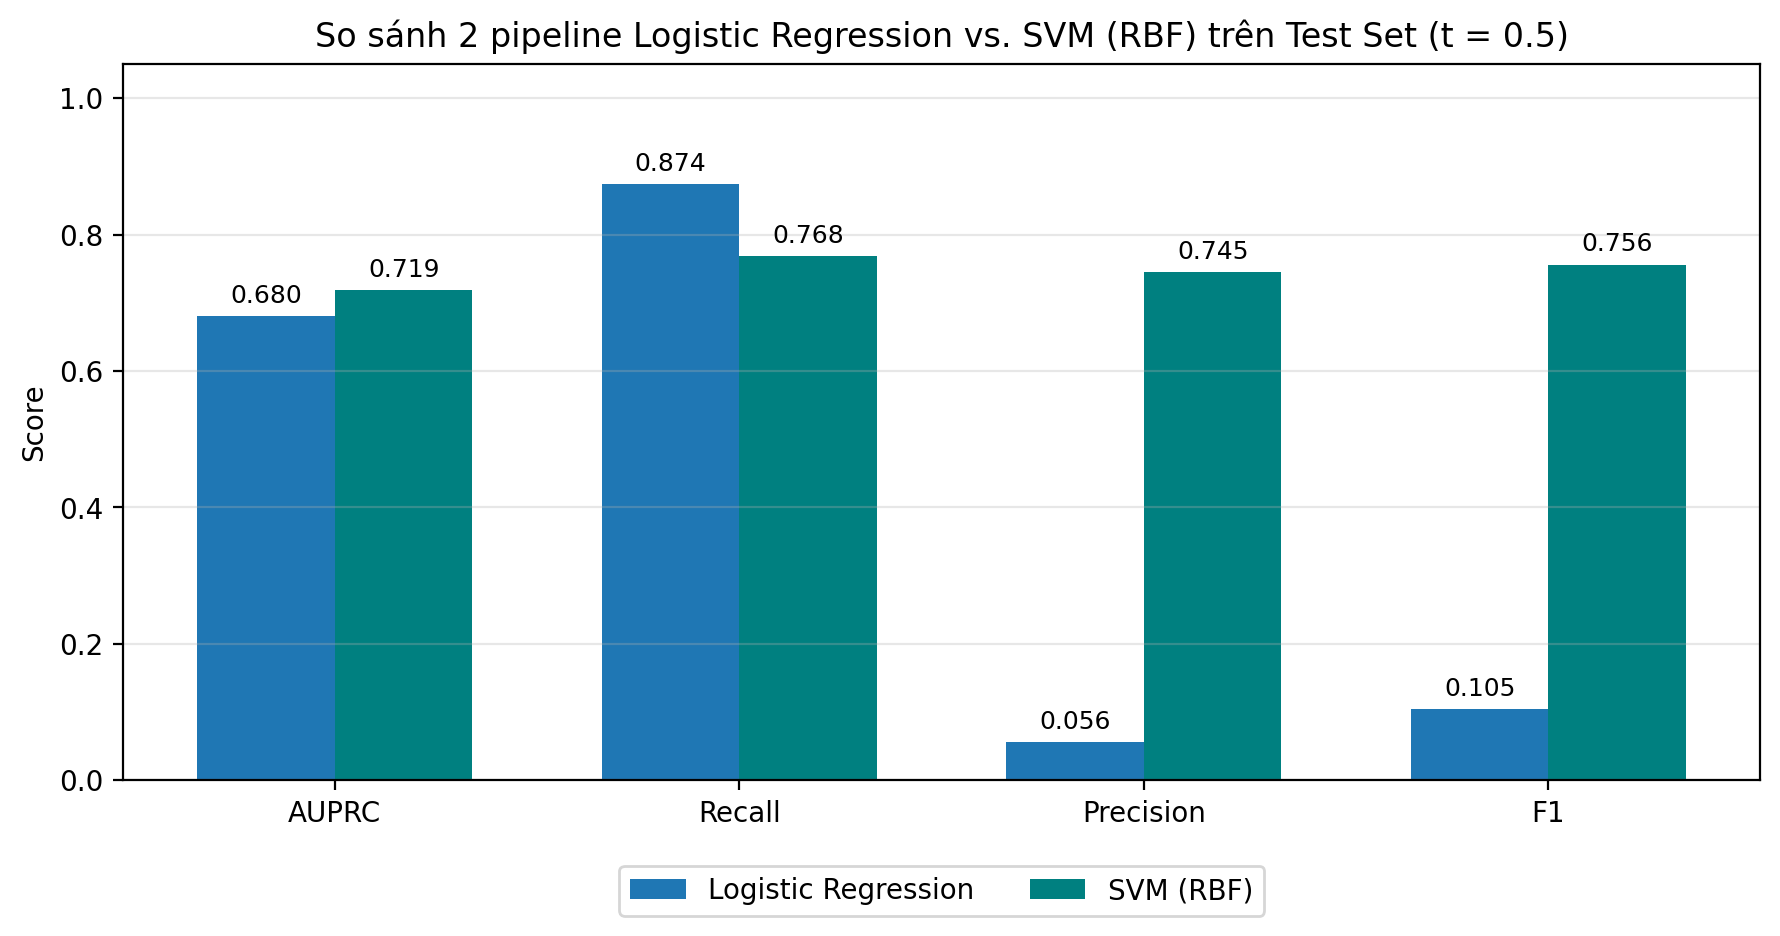

In [4]:
summary_df = pd.DataFrame([
    {"Model": "Logistic Regression", **lr_test_metrics, "Time_s": lr_time},
    {"Model": "SVM (RBF)", **svm_test_metrics, "Time_s": svm_time},
])[["Model", "AUPRC", "Recall", "Precision", "F1", "TP", "FP", "FN", "TN", "Time_s"]]
display(summary_df)

metrics_to_plot = ["AUPRC", "Recall", "Precision", "F1"]
x = np.arange(len(metrics_to_plot))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ["#1f77b4", "#008080"]

for i, (_, row) in enumerate(summary_df.iterrows()):
    vals = [row[m] for m in metrics_to_plot]
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, vals, width, label=row["Model"], color=colors[i])
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

ax.set_title("So sánh 2 pipeline Logistic Regression vs. SVM (RBF) trên Test Set (t = 0.5)")
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=True)

plt.tight_layout()
os.makedirs(FIGURE_DIR, exist_ok=True)
comp_path = FIGURE_DIR / "logistic_vs_svm_comparison.png"
plt.savefig(comp_path, dpi=200, bbox_inches="tight")
plt.close(fig)
print("Saved comparison chart to:", comp_path)
display(Image(filename=str(comp_path)))